<a href="https://colab.research.google.com/github/Akhilkumar-28/Dsa/blob/main/ML_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
url="http://files.grouplens.org/datasets/movielens/ml-100k/u.data"
df=pd.read_csv(url, sep='\t', header=None, names=['user_id', 'item_id', 'rating', 'timestamp'])
print(df.head())

   user_id  item_id  rating  timestamp
0      196      242       3  881250949
1      186      302       3  891717742
2       22      377       1  878887116
3      244       51       2  880606923
4      166      346       1  886397596


In [2]:
df.describe()

,user_id,item_id,rating,timestamp
count,100000.00000,100000.000000,100000.000000,1.000000e+05
mean,462.48475,425.530130,3.529860,8.835289e+08
std,266.61442,330.798356,1.125674,5.343856e+06
min,1.00000,1.000000,1.000000,8.747247e+08
25%,254.00000,175.000000,3.000000,8.794487e+08
50%,447.00000,322.000000,4.000000,8.828269e+08
75%,682.00000,631.000000,4.000000,8.882600e+08
max,943.00000,1682.000000,5.000000,8.932866e+08


In [3]:
print(df)

       user_id  item_id  rating  timestamp
0          196      242       3  881250949
1          186      302       3  891717742
2           22      377       1  878887116
3          244       51       2  880606923
4          166      346       1  886397596
...        ...      ...     ...        ...
99995      880      476       3  880175444
99996      716      204       5  879795543
99997      276     1090       1  874795795
99998       13      225       2  882399156
99999       12      203       3  879959583

[100000 rows x 4 columns]


In [4]:
columns = ['user_id', 'item_id']
print(df[columns])

       user_id  item_id
0          196      242
1          186      302
2           22      377
3          244       51
4          166      346
...        ...      ...
99995      880      476
99996      716      204
99997      276     1090
99998       13      225
99999       12      203

[100000 rows x 2 columns]


In [5]:
import pandas as pd

# -------------------- FILE PATH --------------------
# Base URL for the MovieLens 100k dataset
base_url = "http://files.grouplens.org/datasets/movielens/ml-100k/"

# -------------------- LOAD MAIN DATA --------------------
df = pd.read_csv(
    base_url + "u.data",
    sep="\t",
    names=["user_id", "item_id", "rating", "timestamp"]
)

# -------------------- LOAD USER DATA --------------------
users = pd.read_csv(
    base_url + "u.user",
    sep="|",
    names=["user_id", "age", "gender", "occupation", "zip_code"]
)

# -------------------- LOAD MOVIE DATA --------------------
movies = pd.read_csv(
    base_url + "u.item",
    sep="|",
    encoding="latin-1",
    header=None
)

# Keep only required columns (movie_id + title + genres)
movie_cols = ["item_id", "title"] + [f"genre_{i}" for i in range(22)]
movies = movies.iloc[:, :24]
movies.columns = movie_cols

# -------------------- MERGE ALL --------------------
df = df.merge(users, on="user_id")
df = df.merge(movies, on="item_id")

# -------------------- OPTIONAL: DROP TIMESTAMP --------------------
df = df.drop(columns=["timestamp"])

# -------------------- FINAL DATA --------------------
print(df.head())
print("\nShape:", df.shape)

   user_id  item_id  rating  age gender  occupation zip_code  \
0      196      242       3   49      M      writer    55105   
1      186      302       3   39      F   executive    00000   
2       22      377       1   25      M      writer    40206   
3      244       51       2   28      M  technician    80525   
4      166      346       1   47      M    educator    55113   

                        title      genre_0  genre_1  ... genre_12  genre_13  \
0                Kolya (1996)  24-Jan-1997      NaN  ...        0         0   
1    L.A. Confidential (1997)  01-Jan-1997      NaN  ...        0         1   
2         Heavyweights (1994)  01-Jan-1994      NaN  ...        0         0   
3  Legends of the Fall (1994)  01-Jan-1994      NaN  ...        0         0   
4         Jackie Brown (1997)  01-Jan-1997      NaN  ...        0         0   

   genre_14  genre_15  genre_16  genre_17  genre_18  genre_19  genre_20  \
0         0         0         0         0         0         0    

In [6]:
print(df)

       user_id  item_id  rating  age gender     occupation zip_code  \
0          196      242       3   49      M         writer    55105   
1          186      302       3   39      F      executive    00000   
2           22      377       1   25      M         writer    40206   
3          244       51       2   28      M     technician    80525   
4          166      346       1   47      M       educator    55113   
...        ...      ...     ...  ...    ...            ...      ...   
99995      880      476       3   13      M        student    83702   
99996      716      204       5   36      F  administrator    44265   
99997      276     1090       1   21      M        student    95064   
99998       13      225       2   47      M       educator    29206   
99999       12      203       3   28      F          other    06405   

                              title      genre_0  genre_1  ... genre_12  \
0                      Kolya (1996)  24-Jan-1997      NaN  ...        0 

In [7]:
# -------------------- RENAME GENRES EXACTLY AS README --------------------

movie_cols = [
    "item_id", "title", "release_date", "video_release_date", "imdb_url",
    "unknown", "Action", "Adventure", "Animation", "Children", "Comedy",
    "Crime", "Documentary", "Drama", "Fantasy", "Film-Noir", "Horror",
    "Musical", "Mystery", "Romance", "Sci-Fi", "Thriller", "War", "Western"
]

# Create a mapping dictionary to rename existing genre_X columns in df
rename_map = {f'genre_{i}': movie_cols[i+2] for i in range(22)}

# Apply the renaming to the DataFrame
df.rename(columns=rename_map, inplace=True)

# -------------------- CHECK --------------------
print(df[['title', 'Action', 'Comedy', 'Drama', 'Romance', 'Sci-Fi']].head())

                        title  Action  Comedy  Drama  Romance  Sci-Fi
0                Kolya (1996)       0       1      0        0       0
1    L.A. Confidential (1997)       0       0      0        0       0
2         Heavyweights (1994)       0       1      0        0       0
3  Legends of the Fall (1994)       0       0      1        1       0
4         Jackie Brown (1997)       0       0      1        0       0


In [8]:
print(df)

       user_id  item_id  rating  age gender     occupation zip_code  \
0          196      242       3   49      M         writer    55105   
1          186      302       3   39      F      executive    00000   
2           22      377       1   25      M         writer    40206   
3          244       51       2   28      M     technician    80525   
4          166      346       1   47      M       educator    55113   
...        ...      ...     ...  ...    ...            ...      ...   
99995      880      476       3   13      M        student    83702   
99996      716      204       5   36      F  administrator    44265   
99997      276     1090       1   21      M        student    95064   
99998       13      225       2   47      M       educator    29206   
99999       12      203       3   28      F          other    06405   

                              title release_date  video_release_date  ...  \
0                      Kolya (1996)  24-Jan-1997                 NaN  

In [9]:
# =========================================================
# 1. KNN RECOMMENDER (User-Based Collaborative Filtering)
# =========================================================

import pandas as pd
from sklearn.neighbors import NearestNeighbors
import numpy as np

# load data (df is already loaded and processed in previous cells)
# Using the existing 'df' DataFrame

# create user-item matrix
user_item_matrix = df.pivot_table(index='user_id', columns='item_id', values='rating').fillna(0)

# train KNN model
model_knn = NearestNeighbors(metric='cosine', algorithm='brute')
model_knn.fit(user_item_matrix)

# function to recommend movies
def recommend_movies_knn(user_id, n_neighbors=5):
    user_vec = user_item_matrix.loc[user_id].values.reshape(1, -1)

    distances, indices = model_knn.kneighbors(user_vec, n_neighbors=n_neighbors)

    similar_users = indices.flatten()

    print(f"Similar users for User {user_id}:", similar_users)

    # get movies liked by similar users
    similar_users_ratings = user_item_matrix.iloc[similar_users]
    avg_ratings = similar_users_ratings.mean().sort_values(ascending=False)

    print("\nTop recommended movie IDs:")
    print(avg_ratings.head(10))

# example
recommend_movies_knn(user_id=1)





Similar users for User 1: [  0 915 863 267  91]

Top recommended movie IDs:
item_id
50     5.0
174    5.0
176    4.8
172    4.8
134    4.6
56     4.6
98     4.6
100    4.6
12     4.6
96     4.4
dtype: float64


In [10]:
# =========================================================
# SHOW MOVIE NAMES INSTEAD OF IDS (KNN RECOMMENDER)
# =========================================================

import pandas as pd
from sklearn.neighbors import NearestNeighbors

# -------------------- LOAD DATA --------------------
# The 'df' and 'movies' DataFrames are already loaded and processed in previous cells.
# Re-using the existing 'df' and 'movies' DataFrames.

# -------------------- USER-ITEM MATRIX --------------------
# Use the 'df' DataFrame that was already merged and processed
user_item_matrix = df.pivot_table(
    index='user_id', columns='item_id', values='rating'
).fillna(0)

# -------------------- TRAIN MODEL --------------------
model = NearestNeighbors(metric='cosine', algorithm='brute')
model.fit(user_item_matrix)

# -------------------- RECOMMEND FUNCTION --------------------
def recommend_movies(user_id, n_neighbors=5, top_n=10):
    user_vec = user_item_matrix.loc[user_id].values.reshape(1, -1)

    distances, indices = model.kneighbors(user_vec, n_neighbors=n_neighbors)
    similar_users = indices.flatten()

    print(f"\nSimilar Users: {similar_users}")

    # get average ratings
    similar_ratings = user_item_matrix.iloc[similar_users]
    avg_ratings = similar_ratings.mean().sort_values(ascending=False)

    top_movies = avg_ratings.head(top_n).index

    # map movie IDs to titles using the 'movies' DataFrame loaded earlier
    recommended = movies[movies['item_id'].isin(top_movies)][['item_id','title']]

    print("\nTop Recommendations:")
    for _, row in recommended.iterrows():
        print(f"{row['item_id']} -> {row['title']}")

# -------------------- RUN --------------------
recommend_movies(user_id=1)


Similar Users: [  0 915 863 267  91]

Top Recommendations:
12 -> Usual Suspects, The (1995)
50 -> Star Wars (1977)
56 -> Pulp Fiction (1994)
96 -> Terminator 2: Judgment Day (1991)
98 -> Silence of the Lambs, The (1991)
100 -> Fargo (1996)
134 -> Citizen Kane (1941)
172 -> Empire Strikes Back, The (1980)
174 -> Raiders of the Lost Ark (1981)
176 -> Aliens (1986)


In [11]:
import pandas as pd
from sklearn.neighbors import NearestNeighbors
import numpy as np
from sklearn.model_selection import train_test_split # Import for splitting data
from sklearn.metrics import mean_squared_error

# Assume 'df' is the merged dataframe from previous cells

# 1. Split data into training and testing sets
# Using a common split for recommender systems, e.g., 80/20
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)

# 2. Create user-item matrix for the training data
train_matrix = train_df.pivot_table(index='user_id', columns='item_id', values='rating').fillna(0)

# 3. (Re)-initialize and fit the KNN model on the training matrix for evaluation
# Use a new model instance to avoid interfering with any existing 'model' object
# that might be used for general recommendations based on the full dataset.
model_rmse = NearestNeighbors(metric='cosine', algorithm='brute')
model_rmse.fit(train_matrix)

y_true = []
y_pred = []

# precompute neighbors for ALL users in the training matrix using model_rmse
distances, indices = model_rmse.kneighbors(train_matrix, n_neighbors=5)

# Create a mapping from user_id to its integer index in train_matrix for quick lookup
user_index_map = {user: i for i, user in enumerate(train_matrix.index)}

for _, row in test_df.iterrows():
    user = row['user_id']
    item = row['item_id']
    actual = row['rating']

    # If the user is not in the training set (cold start user), predict a default rating (e.g., 3)
    if user not in user_index_map:
        pred = 3
    else:
        u_idx = user_index_map[user]
        # 'indices[u_idx]' contains the integer indices of similar users within 'train_matrix'
        similar_users_indices = indices[u_idx]

        ratings = []
        for su_idx in similar_users_indices:
            # Check if the item exists in the columns of the training matrix
            if item in train_matrix.columns:
                # Retrieve the rating for the item from the similar user in the training matrix
                r = train_matrix.iloc[su_idx][item]
                if r > 0: # Only consider actual ratings (not fillna=0)
                    ratings.append(r)
            # If item is not in train_matrix columns, or similar user didn't rate it, skip.

        # Predict based on the average of similar users' ratings, or default to 3 if no ratings were found
        pred = np.mean(ratings) if ratings else 3

    y_true.append(actual)
    y_pred.append(pred)

# Calculate RMSE
rmse = np.sqrt(mean_squared_error(y_true, y_pred))

print("KNN RMSE:", rmse)

KNN RMSE: 1.191703525071008


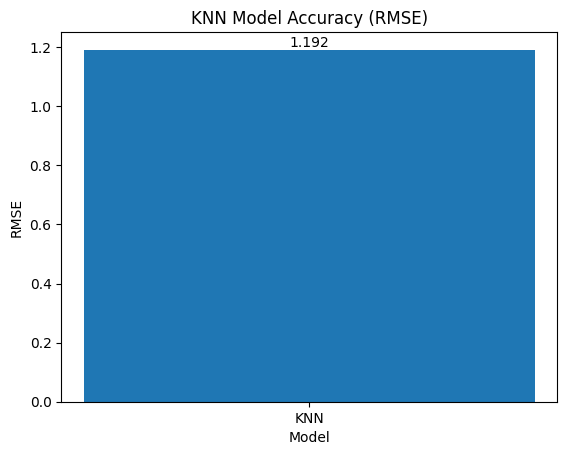

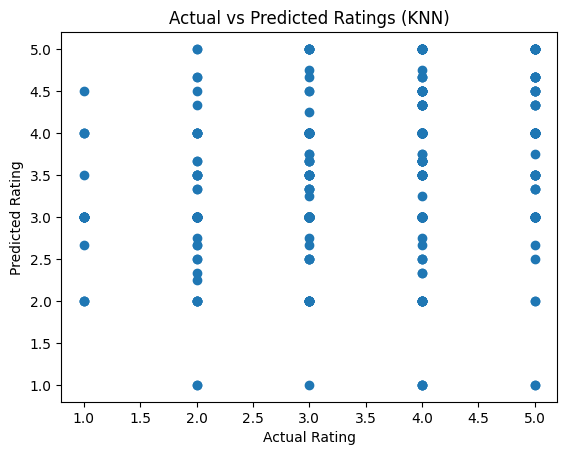

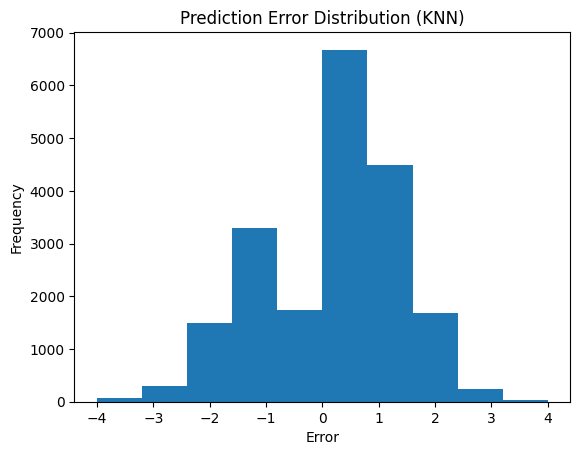

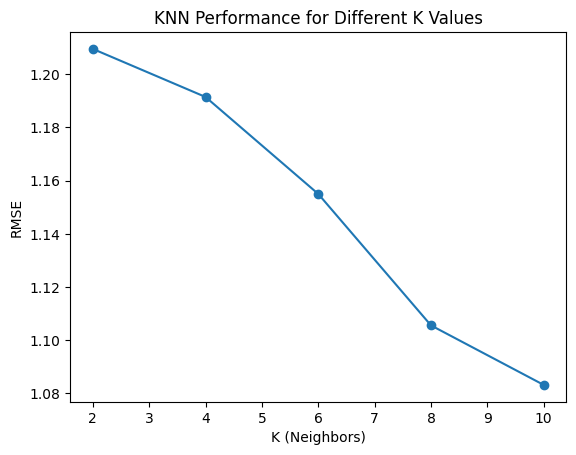

In [12]:
# =========================================================
# KNN VISUALIZATION (FOR PRESENTATION)
# =========================================================

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import mean_squared_error
from sklearn.neighbors import NearestNeighbors

# Define predict_rating function
def predict_rating(user_id, item_id, k):
    global train_matrix, model_rmse # Access global variables

    if user_id not in train_matrix.index:
        return 3.0 # Default rating for cold-start user

    user_vec = train_matrix.loc[user_id].values.reshape(1, -1)

    # Re-calculate neighbors for the specific 'k' using the fitted model
    distances, indices = model_rmse.kneighbors(user_vec, n_neighbors=k)
    similar_users_indices = indices.flatten()

    ratings = []
    for su_idx in similar_users_indices:
        similar_user_actual_id = train_matrix.index[su_idx]

        if item_id in train_matrix.columns:
            r = train_matrix.loc[similar_user_actual_id, item_id]
            if r > 0: # Only consider actual ratings (not fillna=0)
                ratings.append(r)

    return np.mean(ratings) if ratings else 3.0


# -------------------- RMSE BAR --------------------
knn_rmse = rmse  # from your KNN accuracy code

plt.figure()
plt.bar(['KNN'], [knn_rmse])
plt.title("KNN Model Accuracy (RMSE)")
plt.xlabel("Model")
plt.ylabel("RMSE")

plt.text(0, knn_rmse, f"{knn_rmse:.3f}", ha='center', va='bottom')

plt.show()


# =========================================================
# PREDICTED vs ACTUAL (HOW WELL MODEL LEARNS)
# =========================================================

# take small sample for plotting
sample_true = y_true[:500]
sample_pred = y_pred[:500]

plt.figure()
plt.scatter(sample_true, sample_pred)

plt.title("Actual vs Predicted Ratings (KNN)")
plt.xlabel("Actual Rating")
plt.ylabel("Predicted Rating")

plt.show()


# =========================================================
# ERROR DISTRIBUTION
# =========================================================

errors = np.array(y_true) - np.array(y_pred)

plt.figure()
plt.hist(errors)

plt.title("Prediction Error Distribution (KNN)")
plt.xlabel("Error")
plt.ylabel("Frequency")

plt.show()


# =========================================================
# TRAINING VISUALIZATION (DIFFERENT K VALUES)
# =========================================================

k_values = [2, 4, 6, 8, 10]
rmse_list = []

# Take a smaller sample of test_df for faster computation for this visualization
# Ensure test_df is accessible. It is defined in HGi3V-1CxHOC.
sample_test_df = test_df.sample(1000, random_state=42)

for k in k_values:
    preds = []
    true_vals = [] # Also collect true values for this specific sample

    for _, row in sample_test_df.iterrows():
        user = row['user_id']
        item = row['item_id']
        actual = row['rating']

        pred = predict_rating(user, item, k=k)
        preds.append(pred)
        true_vals.append(actual) # Append actual rating for the sample

    rmse_k = np.sqrt(mean_squared_error(true_vals, preds))
    rmse_list.append(rmse_k)

plt.figure()
plt.plot(k_values, rmse_list, marker='o')

plt.title("KNN Performance for Different K Values")
plt.xlabel("K (Neighbors)")
plt.ylabel("RMSE")

plt.show()

### Correlation Matrix

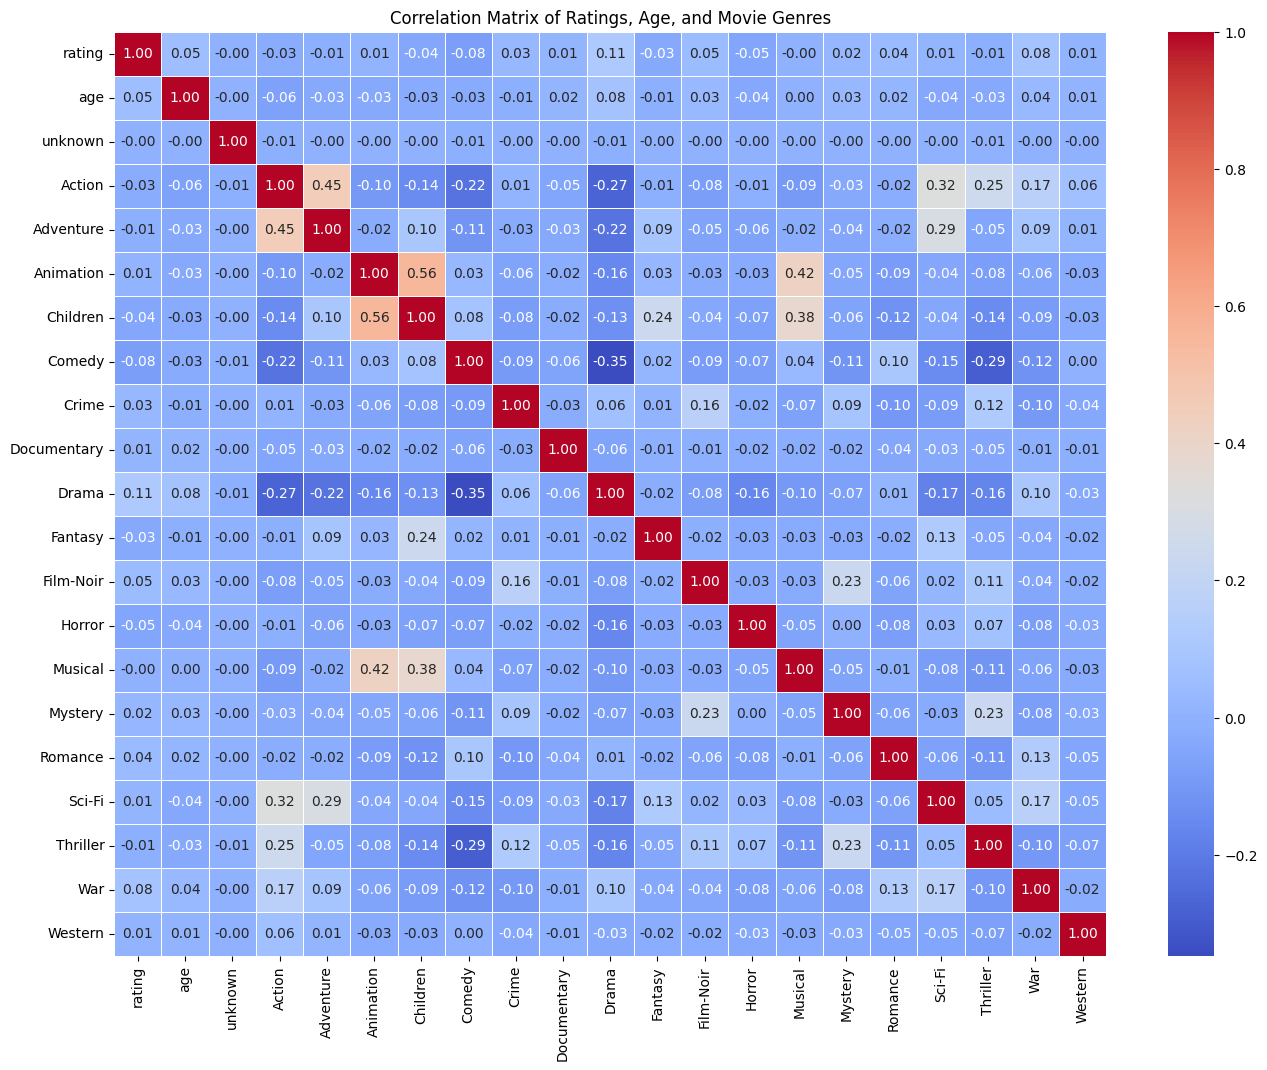

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical columns for correlation, including age and all genre columns
correlation_cols = ['rating', 'age', 'unknown', 'Action', 'Adventure', 'Animation', 'Children', 'Comedy', 'Crime', 'Documentary', 'Drama', 'Fantasy', 'Film-Noir', 'Horror', 'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War', 'Western']

# Calculate the correlation matrix
corr_matrix = df[correlation_cols].corr()

# Plotting the heatmap
plt.figure(figsize=(16, 12))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Correlation Matrix of Ratings, Age, and Movie Genres')
plt.show()

In [14]:
features_3 = ["Action", "Comedy", "Drama"]

In [15]:
features_5 = ["Action", "Comedy", "Drama", "Romance", "Thriller"]

In [16]:
features_10 = [
    "Action", "Adventure", "Animation", "Comedy", "Crime",
    "Drama", "Fantasy", "Romance", "Sci-Fi", "Thriller"
]

In [17]:
target = "rating"

X = df[features_10]   # max features
y = df[target]

In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df[features_10], y, test_size=0.2, random_state=42
)

In [19]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import numpy as np

def run_lr(features):
    model = LinearRegression()
    model.fit(X_train[features], y_train)

    preds = model.predict(X_test[features])
    rmse = np.sqrt(mean_squared_error(y_test, preds))

    print(f"LR ({len(features)} features):", rmse)

run_lr(features_3)
run_lr(features_5)
run_lr(features_10)

LR (3 features): 1.11759618269891
LR (5 features): 1.1164510159009178
LR (10 features): 1.1139403128841308


In [20]:
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

def run_nn(features):
    model = MLPRegressor(hidden_layer_sizes=(64, 32),
                         max_iter=500,
                         random_state=42)

    # Get column indices
    idx = [X_train.columns.get_loc(col) for col in features]

    model.fit(X_train_scaled[:, idx], y_train)
    preds = model.predict(X_test_scaled[:, idx])

    rmse = np.sqrt(mean_squared_error(y_test, preds))
    print(f"NN ({len(features)} features):", rmse)

run_nn(features_3)
run_nn(features_5)
run_nn(features_10)

NN (3 features): 1.1172747553303222
NN (5 features): 1.1096687255558348
NN (10 features): 1.0987233635182097


In [21]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error
import numpy as np

def run_knn(features, k=5):
    # Get column indices
    idx = [X.columns.get_loc(col) for col in features]

    model = KNeighborsRegressor(n_neighbors=k, metric='euclidean')

    model.fit(X_train_scaled[:, idx], y_train)

    preds = model.predict(X_test_scaled[:, idx])

    rmse = np.sqrt(mean_squared_error(y_test, preds))

    print(f"KNN Regression ({len(features)} features, k={k}) RMSE:", rmse)

# Run for 3, 5, 10 features
run_knn(features_3)
run_knn(features_5)
run_knn(features_10)

KNN Regression (3 features, k=5) RMSE: 1.2277304264373348


In [ ]:
import matplotlib.pyplot as plt

features = [3, 5, 10]

# Replace with your actual RMSE outputs
lr_rmse = [1.11759618269891, 1.1164510159009178, 1.1139403128841308]
nn_rmse = [1.1172747553303222, 1.1096687255558348, 1.0987233635182097]
knn_rmse = [1.2277304264373348, 1.2061691423676864, 1.1629754941528219]

plt.figure()

plt.plot(features, lr_rmse, marker='o', label='Linear Regression')
plt.plot(features, nn_rmse, marker='o', label='Neural Network')
plt.plot(features, knn_rmse, marker='o', label='KNN Regression')

plt.xlabel("Number of Features")
plt.ylabel("RMSE")
plt.title("RMSE Comparison Across Models")
plt.legend()
plt.grid()

plt.show()

corrolation matrix-3fetaures


In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Select features
corr_3 = df[features_3 + ['rating']].corr()

plt.figure()
sns.heatmap(corr_3, annot=True)
plt.title("Correlation Matrix (3 Features)")
plt.show()

corrolation matrix-5 fetaures


In [ ]:
corr_5 = df[features_5 + ['rating']].corr()

plt.figure()
sns.heatmap(corr_5, annot=True)
plt.title("Correlation Matrix (5 Features)")
plt.show()

corrolation matrix-10 fetaures


In [ ]:
corr_10 = df[features_10 + ['rating']].corr()

plt.figure()
sns.heatmap(corr_10, annot=False)  # keep False to avoid clutter
plt.title("Correlation Matrix (10 Features)")
plt.show()